# EP N°2 — Deep Learning (AVY1103)
## Comparación de arquitecturas CNN + selección del modelo para la API

Esta versión reemplaza al notebook anterior de una sola CNN: ahora se
**comparan 3 arquitecturas distintas** sobre el mismo dataset y se elige la
ganadora con evidencia (métricas + curvas) — tal como pide la pauta de
Presentación del EP2: *"se debe incluir gráficos que muestren las ventajas
de una combinación modelo-matrices sobre otra"*.

**Restricción fija:** el formato de imagen se mantiene en **128×128×3**
para las 3 arquitecturas — no se varía, porque es el formato exacto que la
app móvil va a enviarle a la API más adelante (ítem 3 del Encargo). Lo que
sí se compara es **el modelo**.

**Plan:**
1. Pipeline de datos (carga, normalización, aumento de datos)
2. Train / Val / Test (60/20/20)
3. Tres arquitecturas de CNN a comparar
4. Entrenamiento bajo las mismas condiciones
5. Comparación por evidencia y selección del ganador
6. Evaluación final del ganador en Test (matriz de confusión + reporte)
7. Guardar el modelo ganador (para la API)


## 1. Importar librerías

In [1]:
import os
import glob
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

from PIL import Image

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Versión de TensorFlow:", keras.__version__)


Versión de TensorFlow: 3.13.2


## 2. Preparación del dataset

### Características de las imágenes digitales (IL 2.1)

- Una imagen a color es una **matriz** de forma `(alto, ancho, canales)`,
  con valores de intensidad entre 0 y 255 por canal (R, G, B).
- La **resolución** define el nivel de detalle disponible; los
  **canales de color** multiplican la cantidad de información.
- Una **CNN** aprovecha la estructura espacial 2D de la imagen mediante
  filtros convolucionales — a diferencia de una red densa, que aplana todo
  a un vector y pierde la relación de vecindad entre píxeles.

Usamos el mismo dataset propio del curso (fotos organizadas en carpetas
por alumno), publicado en Kaggle.

In [2]:
import kagglehub

DATASET_PATH = kagglehub.dataset_download("matiasosvaldog/data-set-grupo")
print("Path al dataset:", DATASET_PATH)


100%|██████████| 41.3M/41.3M [00:00<00:00, 76.3MB/s]

Extracting files...


Path al dataset: /root/.cache/kagglehub/datasets/matiasosvaldog/data-set-grupo/versions/1


In [3]:
ALTO, ANCHO, CANALES = 128, 128, 3
EXTENSIONES = ("*.jpg", "*.jpeg", "*.png")

rutas_imagenes = []
for ext in EXTENSIONES:
    rutas_imagenes.extend(glob.glob(os.path.join(DATASET_PATH, "**", ext), recursive=True))
rutas_imagenes = sorted(rutas_imagenes)

print(f"Total de imágenes encontradas: {len(rutas_imagenes)}")


Total de imágenes encontradas: 150


In [4]:
from PIL import Image, ImageOps

def obtener_etiqueta(ruta):
    '''La etiqueta es el nombre de la carpeta que contiene la imagen (nombre del alumno).'''
    return os.path.basename(os.path.dirname(ruta))

def cargar_imagen(ruta, tamano=(ALTO, ANCHO)):
    with Image.open(ruta) as img:
        img = ImageOps.exif_transpose(img).convert("RGB").resize(tamano, Image.LANCZOS)
        return np.asarray(img, dtype=np.uint8)

x_datos = np.stack([cargar_imagen(r) for r in rutas_imagenes])
etiquetas_texto = [obtener_etiqueta(r) for r in rutas_imagenes]

clases = sorted(set(etiquetas_texto))
num_clases = len(clases)
clase_a_indice = {nombre: i for i, nombre in enumerate(clases)}
y_datos = np.array([clase_a_indice[e] for e in etiquetas_texto])

# Normalización: de [0, 255] a [0, 1]
x_datos = x_datos.astype("float32") / 255.0

print(f"x_datos: shape={x_datos.shape}, dtype={x_datos.dtype}")
print(f"Número de clases (alumnos): {num_clases}")


x_datos: shape=(150, 128, 128, 3), dtype=float32
Número de clases (alumnos): 15


In [5]:
from sklearn.datasets import fetch_lfw_people

# Caras de personas que NO están en el curso (dataset público LFW)
lfw = fetch_lfw_people(min_faces_per_person=20, color=True, resize=1.0,
                       slice_=(slice(0, 250), slice(0, 250)))
imgs = lfw.images
if imgs.max() <= 1.5:
    imgs = imgs * 255.0

rng = np.random.default_rng(SEED)
elegidos = []
for persona in np.unique(lfw.target):                 # máx. 2 fotos por persona
    idxs = np.where(lfw.target == persona)[0]
    elegidos.extend(rng.choice(idxs, size=min(2, len(idxs)), replace=False))
elegidos = rng.permutation(elegidos)[:45]

x_desc = np.stack([
    np.asarray(Image.fromarray(imgs[i].clip(0, 255).astype("uint8")).resize((ANCHO, ALTO), Image.LANCZOS))
    for i in elegidos
]).astype("float32") / 255.0

clases = clases + ["desconocido"]
num_clases = len(clases)
x_datos = np.concatenate([x_datos, x_desc])
y_datos = np.concatenate([y_datos, np.full(len(x_desc), num_clases - 1)])

print(f"Ahora hay {num_clases} clases y {len(x_datos)} imágenes (45 son 'desconocido')")

Ahora hay 16 clases y 195 imágenes (45 son 'desconocido')


## 3. División Train / Validation / Test (60/20/20)

El Test se reserva aparte y no participa del entrenamiento ni de la
selección de arquitectura — se usa una sola vez, al final.

In [6]:
indices = np.arange(len(y_datos))

idx_trainval, idx_test = train_test_split(indices, test_size=0.20, random_state=SEED, stratify=y_datos)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, random_state=SEED, stratify=y_datos[idx_trainval])

x_train, y_train = x_datos[idx_train], y_datos[idx_train]
x_val, y_val = x_datos[idx_val], y_datos[idx_val]
x_test, y_test = x_datos[idx_test], y_datos[idx_test]

print(f"Train: {len(idx_train)} | Val: {len(idx_val)} | Test: {len(idx_test)}")


Train: 117 | Val: 39 | Test: 39


## 4. Pipeline de aumento de datos

Se activa solo durante el entrenamiento (se apaga automáticamente en
`predict`/`evaluate`). Con ~6 fotos de entrenamiento por alumno, generar
variaciones leves en cada época ayuda a no memorizar las fotos exactas.

In [7]:
aumento_datos = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
], name="aumento_datos")


## 5. Tres arquitecturas de CNN a comparar

Mismo criterio que usamos en la EA2: tres variantes que aíslan el efecto
de BatchNorm y Dropout, todas con el mismo número de bloques
convolucionales para que la comparación sea justa.

- **A — Básica:** Conv2D + MaxPooling ×3, sin BatchNorm ni Dropout.
- **B — Con BatchNorm:** igual que A, + `BatchNormalization()` después de
  cada convolución — estabiliza y suele acelerar el entrenamiento.
- **C — BatchNorm + Dropout:** igual que B, + Dropout entre bloques y
  antes de la salida — regularización extra, relevante porque el dataset
  es muy chico (90 fotos de entrenamiento, 15 clases).

In [8]:
def construir_arquitectura_A(input_shape, num_clases):
    '''Básica: Conv + Pooling x3, sin BatchNorm ni Dropout.'''
    return keras.Sequential([
        layers.Input(shape=input_shape),
        aumento_datos,

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_clases, activation="softmax"),
    ], name="A_basica")


def construir_arquitectura_B(input_shape, num_clases):
    '''Con BatchNorm después de cada bloque convolucional.'''
    return keras.Sequential([
        layers.Input(shape=input_shape),
        aumento_datos,

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(2),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(2),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(2),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(num_clases, activation="softmax"),
    ], name="B_batchnorm")


def construir_arquitectura_C(input_shape, num_clases):
    '''BatchNorm + Dropout: regularización extra para dataset chico.'''
    return keras.Sequential([
        layers.Input(shape=input_shape),
        aumento_datos,

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(2),
        layers.Dropout(0.2),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(2),
        layers.Dropout(0.2),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.BatchNormalization(momentum=0.9),
        layers.MaxPooling2D(2),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(num_clases, activation="softmax"),
    ], name="C_batchnorm_dropout")


CONSTRUCTORES = {
    "A_basica": construir_arquitectura_A,
    "B_batchnorm": construir_arquitectura_B,
    "C_batchnorm_dropout": construir_arquitectura_C,
}

input_shape = (ALTO, ANCHO, CANALES)
construir_arquitectura_C(input_shape, num_clases).summary()


Model: "C_batchnorm_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento_datos (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │         2,064 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,290,640 (16.37 MB)

 Trainable params: 4,290,192 (16.37 MB)

 Non-trainable params: 448 (1.75 KB)

## 6. Hiperparámetros comunes

Mismos para las 3 arquitecturas — si no, la comparación no sería justa.

| Parámetro | Valor | Por qué |
|---|---|---|
| Learning rate | `1e-3` | Valor por defecto de Adam |
| Batch size | `8` | Dataset chico (90 fotos de entrenamiento) |
| Épocas | `30` (con EarlyStopping) | Techo alto, EarlyStopping corta antes si no mejora |

In [9]:
LEARNING_RATE = 1e-3
BATCH_SIZE = 8
EPOCHS = 30


## 7. Entrenamiento de las tres arquitecturas

In [10]:
resultados = []
historiales = {}
modelos_entrenados = {}

for nombre, constructor in CONSTRUCTORES.items():
    print(f"\n=== Entrenando arquitectura: {nombre} ===")

    modelo = constructor(input_shape, num_clases)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True,
    )

    inicio = time.time()
    history = modelo.fit(
        x_train, y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=2,
    )
    tiempo = time.time() - inicio

    historiales[nombre] = history
    modelos_entrenados[nombre] = modelo

    resultados.append({
        "arquitectura": nombre,
        "epocas_corridas": len(history.history["loss"]),
        "train_accuracy": history.history["accuracy"][-1],
        "val_accuracy": history.history["val_accuracy"][-1],
        "val_loss": history.history["val_loss"][-1],
        "n_parametros": modelo.count_params(),
        "tiempo_seg": round(tiempo, 1),
    })

print("\n✅ Entrenamiento de las 3 arquitecturas finalizado.")



=== Entrenando arquitectura: A_basica ===
Epoch 1/30
15/15 - 5s - 362ms/step - accuracy: 0.1880 - loss: 2.9032 - val_accuracy: 0.2308 - val_loss: 2.4588
Epoch 2/30
15/15 - 3s - 218ms/step - accuracy: 0.2650 - loss: 2.3144 - val_accuracy: 0.4359 - val_loss: 1.9859
Epoch 3/30
15/15 - 4s - 245ms/step - accuracy: 0.4444 - loss: 1.8697 - val_accuracy: 0.4615 - val_loss: 1.6858
Epoch 4/30
15/15 - 3s - 214ms/step - accuracy: 0.5726 - loss: 1.5139 - val_accuracy: 0.5385 - val_loss: 2.1990
Epoch 5/30
15/15 - 3s - 216ms/step - accuracy: 0.6838 - loss: 0.9952 - val_accuracy: 0.5897 - val_loss: 2.6356
Epoch 6/30
15/15 - 6s - 367ms/step - accuracy: 0.7607 - loss: 0.7633 - val_accuracy: 0.7692 - val_loss: 0.9486
Epoch 7/30
15/15 - 5s - 307ms/step - accuracy: 0.8376 - loss: 0.5286 - val_accuracy: 0.7949 - val_loss: 1.2236
Epoch 8/30
15/15 - 3s - 209ms/step - accuracy: 0.8803 - loss: 0.3801 - val_accuracy: 0.7692 - val_loss: 1.5722
Epoch 9/30
15/15 - 5s - 337ms/step - accuracy: 0.8889 - loss: 0.3407 

## 8. Comparación por evidencia: métricas y curvas de aprendizaje

In [11]:
df_resultados = pd.DataFrame(resultados).sort_values("val_accuracy", ascending=False).reset_index(drop=True)
df_resultados


,arquitectura,epocas_corridas,train_accuracy,val_accuracy,val_loss,n_parametros,tiempo_seg
0,A_basica,12,0.905983,0.769231,1.264708,4289744,52.7
1,C_batchnorm_dropout,16,0.547009,0.717949,1.111408,4290640,74.4
2,B_batchnorm,10,0.897436,0.589744,4.366094,4290640,47.4


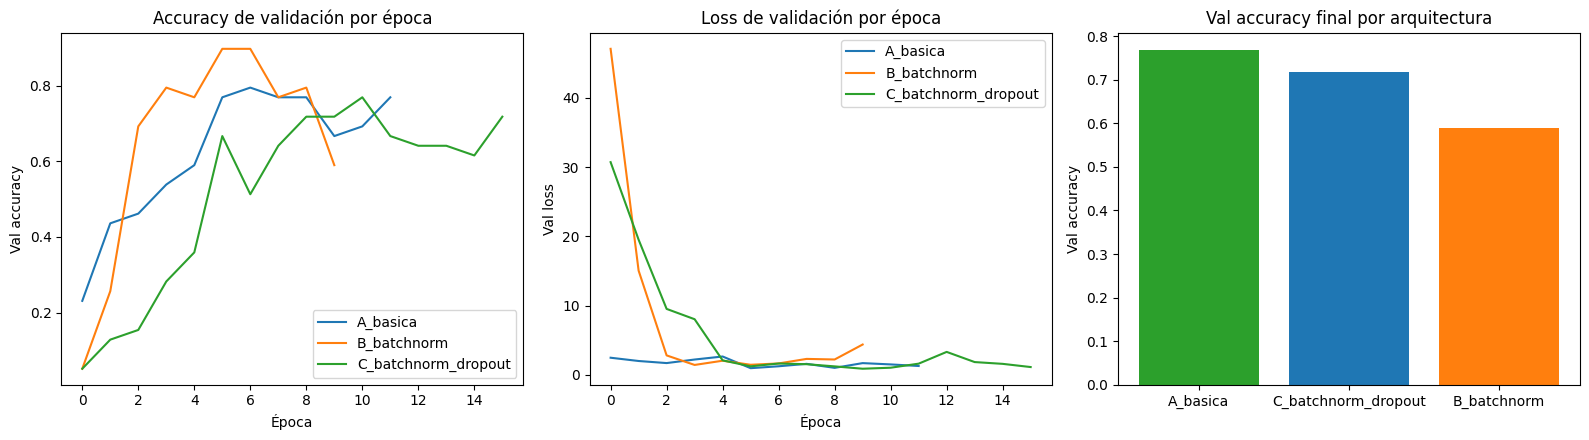

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for nombre, history in historiales.items():
    axes[0].plot(history.history["val_accuracy"], label=nombre)
    axes[1].plot(history.history["val_loss"], label=nombre)

axes[0].set_title("Accuracy de validación por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Val accuracy"); axes[0].legend()

axes[1].set_title("Loss de validación por época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Val loss"); axes[1].legend()

axes[2].bar(df_resultados["arquitectura"], df_resultados["val_accuracy"], color=["#2ca02c", "#1f77b4", "#ff7f0e"])
axes[2].set_title("Val accuracy final por arquitectura")
axes[2].set_ylabel("Val accuracy")

plt.tight_layout()
plt.show()


### Selección del modelo ganador
El modelo elegido es el de mayor `val_accuracy` — la arquitectura que
mejor generalizó a datos que no vio durante el ajuste de pesos. Este es
el modelo que luego se envuelve en la API.

In [13]:
mejor_arquitectura = df_resultados.iloc[0]["arquitectura"]
modelo_final = modelos_entrenados[mejor_arquitectura]

print(f"Arquitectura ganadora: {mejor_arquitectura}")
print(f"Val accuracy: {df_resultados.iloc[0]['val_accuracy']:.4f}")
print(f"Val loss: {df_resultados.iloc[0]['val_loss']:.4f}")
print(f"Parámetros: {df_resultados.iloc[0]['n_parametros']:,}")


Arquitectura ganadora: A_basica
Val accuracy: 0.7692
Val loss: 1.2647
Parámetros: 4,289,744


## 9. Evaluación final en el conjunto de Test (una sola vez, IL 2.4)

In [14]:
test_loss, test_acc = modelo_final.evaluate(x_test, y_test, verbose=0)
print(f"Combinación evaluada: {mejor_arquitectura}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")


Combinación evaluada: A_basica
Test accuracy: 0.8462
Test loss: 0.8735


In [19]:
probs = modelo_final.predict(x_test, verbose=0)
conf = probs.max(axis=1)
pred = probs.argmax(axis=1)
idx_desc = num_clases - 1
es_desc = (y_test == idx_desc)

print(f"Test: {(~es_desc).sum()} fotos de alumnos, {es_desc.sum()} de desconocidos\n")
print("umbral | alumnos aceptados bien | desconocidos rechazados")
for u in [0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]:
    ok_alumnos = ((pred == y_test) & (conf >= u) & ~es_desc).sum() / max((~es_desc).sum(), 1)
    rech_desc = (((pred == idx_desc) | (conf < u)) & es_desc).sum() / max(es_desc.sum(), 1)
    print(f"{u:.2f}   |        {ok_alumnos:.0%}            |        {rech_desc:.0%}")

Test: 30 fotos de alumnos, 9 de desconocidos

umbral | alumnos aceptados bien | desconocidos rechazados
0.50   |        80%            |        100%
0.60   |        73%            |        100%
0.70   |        63%            |        100%
0.75   |        63%            |        100%
0.80   |        57%            |        100%
0.85   |        50%            |        100%
0.90   |        43%            |        100%


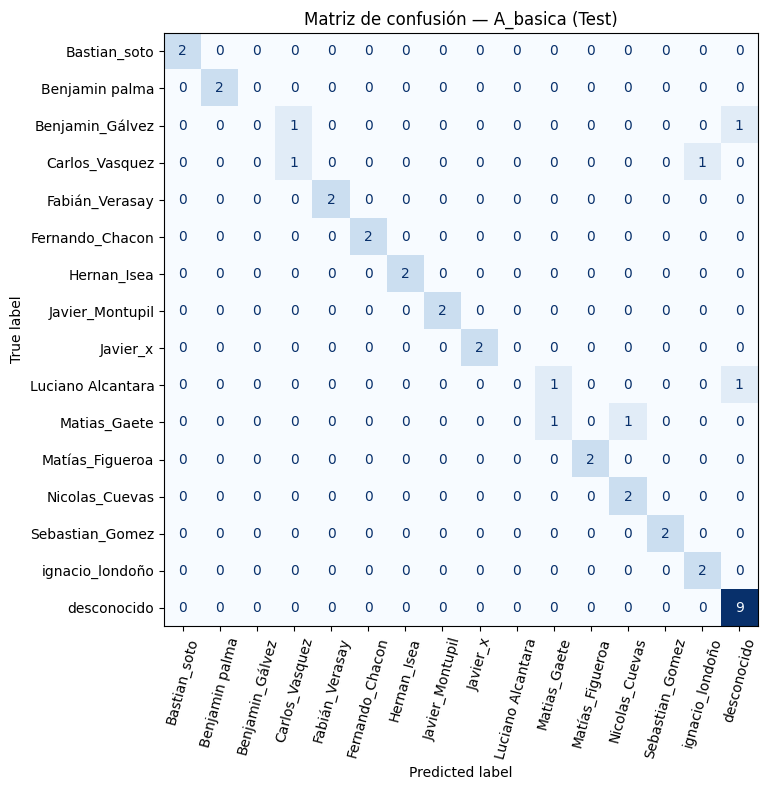

In [15]:
y_pred_probs = modelo_final.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred, labels=range(num_clases))
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases)
disp.plot(ax=ax, xticks_rotation=75, colorbar=False, cmap="Blues")
plt.title(f"Matriz de confusión — {mejor_arquitectura} (Test)")
plt.tight_layout()
plt.show()


In [16]:
print("Reporte de clasificación:\n")
print(classification_report(y_test, y_pred, labels=range(num_clases), target_names=clases, zero_division=0))


Reporte de clasificación:

                   precision    recall  f1-score   support

     Bastian_soto       1.00      1.00      1.00         2
   Benjamin palma       1.00      1.00      1.00         2
  Benjamin_Gálvez       0.00      0.00      0.00         2
   Carlos_Vasquez       0.50      0.50      0.50         2
   Fabián_Verasay       1.00      1.00      1.00         2
  Fernando_Chacon       1.00      1.00      1.00         2
      Hernan_Isea       1.00      1.00      1.00         2
  Javier_Montupil       1.00      1.00      1.00         2
         Javier_x       1.00      1.00      1.00         2
Luciano Alcantara       0.00      0.00      0.00         2
     Matias_Gaete       0.50      0.50      0.50         2
  Matías_Figueroa       1.00      1.00      1.00         2
   Nicolas_Cuevas       0.67      1.00      0.80         2
  Sebastian_Gomez       1.00      1.00      1.00         2
  ignacio_londoño       0.67      1.00      0.80         2
      desconocido       0.82

## 10. Guardar el modelo ganador

Este archivo es el que la **API** del EP2 va a cargar: recibe una imagen
convertida en matriz 128×128×3, y devuelve el nombre del alumno (o indica
que no está en la base).

In [17]:
modelo_final.save("modelo_cnn_rostros_curso.keras")

import json
with open("clases_cnn_rostros.json", "w", encoding="utf-8") as f:
    json.dump(clases, f, ensure_ascii=False, indent=2)

print(f"Modelo ganador ({mejor_arquitectura}) guardado en: modelo_cnn_rostros_curso.keras")
print("Lista de clases guardada en: clases_cnn_rostros.json")


Modelo ganador (A_basica) guardado en: modelo_cnn_rostros_curso.keras
Lista de clases guardada en: clases_cnn_rostros.json


## 11. Conclusión

Completar con base en la tabla y los gráficos anteriores:

- **¿Qué arquitectura ganó y por qué?** ¿Fue el BatchNorm, el Dropout, o
  la combinación de ambos?
- **¿Alguna arquitectura mostró overfitting claro en las curvas de
  val_loss?** (la básica, sin regularización, es la candidata más
  probable — mismo patrón que vimos en el EP1 con dataset chico)
- **¿El tiempo de entrenamiento y la cantidad de parámetros justifican la
  arquitectura más compleja?**
- **¿Qué alumno confunde más el modelo según la matriz de confusión?**
  ¿Coincide con lo que ya habíamos visto en el EP1?

### Próximo paso
Con `modelo_cnn_rostros_curso.keras` ya guardado, seguimos con:
1. Agregar el umbral de confianza para que la API pueda responder
   "no está en la base de datos".
2. Envolver el modelo en la API (FastAPI).
3. Conectar la app móvil.


In [18]:
from google.colab import files
files.download("modelo_cnn_rostros_curso.keras")
files.download("clases_cnn_rostros.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>